# Rossmann Store Sales — Phase 5: Final Scoring, Error Analysis, and Write-up

The only phase that touches `test.csv`. Everything before this was developed and selected against a held-out slice of `train.csv`, so the pipeline applied here is frozen: hyperparameters, ensemble weights, and the shrink factor all come from `phase47_params.json`, fitted on the inner split back in Phase 4.7.

**Two things legitimately change now that selection is over:**

1. **The final model trains on all of `train.csv`**, not just `train_fold`. The 42-day validation window was held out to make model choices honest; those choices are made, so withholding that data from the final fit would only throw away six weeks of the most recent — and most relevant — history.
2. **The forecast horizon becomes 48 days, not 42.** `test.csv` runs 2015-08-01 to 2015-09-17, which is 48 days past the last training date. Phase 4.6's whole lesson was that training rows must be as stale as served rows, so the training origins are re-tiled at 48 days to match. Training at 42 and serving at 48 would reintroduce exactly the mismatch that phase removed.

Both are consequences of `test.csv`'s actual shape, which is only knowable now — and neither is a model *choice* re-made against the test set.

In [1]:
import json, time, warnings
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
pio.templates.default = "plotly_white"
warnings.filterwarnings("ignore")

import lightgbm as lgb
from catboost import CatBoostRegressor

from rossmann_features import (
    prepare_store_table, add_features, NUMERIC_COLS,
    fit_store_dow_promo_mean, predict_store_dow_promo_mean,
    fit_store_target_encoding, add_store_target_encoding,
)
import rossmann_features_v2 as f2
from rossmann_nn import rmspe

PARAMS = json.load(open("phase47_params.json"))
LGB_P = {k: (int(v) if k in ("num_leaves", "min_child_samples", "bagging_freq") else v)
         for k, v in PARAMS["lgb"].items()}
LGB_ITERS = int(PARAMS["lgb_iters"])
CB_P = {k: (int(v) if k in ("iterations", "depth") else v) for k, v in PARAMS["catboost"].items()}
WEIGHTS = dict(zip(PARAMS["members"], PARAMS["ensemble_weights"]))
FACTOR = PARAMS["ensemble_factor"]
P = PARAMS["weight_exponent_p"]
print("frozen from Phase 4.7 (inner-split fits):")
print("  lgb", LGB_P, "iters", LGB_ITERS)
print("  cat", CB_P)
print("  ensemble weights", WEIGHTS, "| shrink factor", round(FACTOR, 3), "| loss weight p =", P)

train = pd.read_csv("train.csv", parse_dates=["Date"], low_memory=False, dtype={"StateHoliday": str})
test = pd.read_csv("test.csv", parse_dates=["Date"], dtype={"StateHoliday": str})
store_prepared = prepare_store_table(pd.read_csv("store.csv"))

TRAIN_END = train["Date"].max()
HORIZON = int((test["Date"].max() - TRAIN_END).days)
print(f"\ntrain ends {TRAIN_END.date()} | test {test.Date.min().date()} -> {test.Date.max().date()}"
      f" | horizon = {HORIZON} days")
print(f"test rows {len(test)} | stores {test.Store.nunique()} of {train.Store.nunique()}"
      f" | Open nulls {int(test.Open.isna().sum())}")

frozen from Phase 4.7 (inner-split fits):
  lgb {'learning_rate': 0.02, 'num_leaves': 255, 'min_child_samples': 50, 'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'bagging_freq': 1, 'lambda_l2': 10.0} iters 1855
  cat {'iterations': 1500, 'learning_rate': 0.03, 'depth': 10}
  ensemble weights {'lgb': 0.75, 'cat': 0.25, 'hgb': 0.0} | shrink factor 0.995 | loss weight p = 1



train ends 2015-07-31 | test 2015-08-01 -> 2015-09-17 | horizon = 48 days
test rows 41088 | stores 856 of 1115 | Open nulls 11


In [2]:
# Full-history feature build. Everything Sales-derived comes from ALL of train.csv; the
# test rows get the same frozen-origin treatment validation always got, with the origin
# set to the last training date.
train_feat = add_features(train.copy(), store_prepared)
test_feat = add_features(test.copy(), store_prepared)   # also fills test.csv's 11 null Open as 1
history_open = train_feat[train_feat["Open"] == 1]
fit_rows = train_feat[(train_feat["Open"] == 1) & (train_feat["Sales"] > 0)].copy()

# Schedule features span train+test so promo/holiday distances are correct across the
# boundary. Uses only Promo/StateHoliday/SchoolHoliday/Open/Date -- all present in
# test.csv, none derived from Sales.
panel_cols = ["Store", "Date", "Promo", "StateHoliday", "SchoolHoliday", "Open"]
panel = f2.add_schedule_features(pd.concat([train_feat[panel_cols], test_feat[panel_cols]],
                                            ignore_index=True))
sched_lookup = panel[["Store", "Date"] + f2.SCHEDULE_COLS]

sd = fit_store_dow_promo_mean(history_open)
gm = history_open["Sales"].mean()
enc = fit_store_target_encoding(history_open)
gml = np.log1p(history_open["Sales"]).mean()
roll = f2.build_daily_rolling_table(history_open)
trends = f2.fit_store_trend(history_open)

def build(df, mode, cutoff, horizon):
    df = f2.assign_training_origins(df, cutoff, horizon=horizon) if mode == "training" else \
         f2.assign_fixed_origin(df, cutoff)
    df = f2.attach_rolling(df, roll, fallback_source=history_open)
    fb = predict_store_dow_promo_mean(df, sd, gm)
    df = f2.add_yearago_features(df, history_open, fb)
    df = add_store_target_encoding(df, enc, gml)
    n = len(df)
    df = df.merge(sched_lookup, on=["Store", "Date"], how="left")
    assert len(df) == n, "schedule merge changed row count"
    return f2.add_promo2_duration(f2.add_store_trend(df, trends))

t0 = time.time()
FIT = build(fit_rows.copy(), "training", TRAIN_END, HORIZON)
TEST = build(test_feat.copy(), "frozen", TRAIN_END, HORIZON)
print(f"built in {time.time()-t0:.0f}s | fit {FIT.shape} | test {TEST.shape}")

CAT = ["Store", "DayOfWeek", "Month", "StoreType", "Assortment", "StateHoliday"]
NUM = NUMERIC_COLS + f2.LAG_COLS_V2 + f2.SCHEDULE_COLS + f2.EXTRA_NUMERIC_COLS
FEATS = CAT + NUM
letters = sorted(set(train_feat["StoreType"]) | set(train_feat["Assortment"])
                 | set(train_feat["StateHoliday"].astype(str)) | set(test_feat["StateHoliday"].astype(str)))
code = {v: i for i, v in enumerate(letters)}
for d in (FIT, TEST):
    for c in ["StoreType", "Assortment", "StateHoliday"]:
        d[c] = d[c].astype(str).map(code)
    for c in CAT:
        d[c] = d[c].astype("int32")

built in 1s | fit (844338, 45) | test (41088, 44)


In [3]:
# Pre-flight checks. A silent feature bug here is unrecoverable -- there is no second
# evaluation to catch it.
print("1. no NaNs in model inputs      :", int(FIT[FEATS].isna().sum().sum()) == 0,
      "|", int(TEST[FEATS].isna().sum().sum()) == 0)
print("2. train horizons cover serving :", FIT.HorizonDay.min(), "-", FIT.HorizonDay.max(),
      "vs test", TEST.HorizonDay.min(), "-", TEST.HorizonDay.max())
print("3. every test origin is the cutoff:", (TEST.Origin == TRAIN_END).all())
print("4. no test store unseen in train:", len(set(TEST.Store) - set(FIT.Store)) == 0)
print("5. test rows preserved          :", len(TEST) == len(test),
      "| Id order intact:", (TEST.Id.values == test.Id.values).all())
print("6. no Sales/Customers leaked in :",
      not any(c in FEATS for c in ["Sales", "Customers"]))

# The lag features are built from history only, so they must be identical whether or not
# the target frame carries Sales/Customers at all -- test.csv has neither.
print("7. test frame genuinely lacks Sales/Customers:",
      "Sales" not in test.columns and "Customers" not in test.columns)

# Feature distributions: test should look like training, apart from the deliberate
# staleness of the rolling window (frozen at one origin for all 48 days).
comp = pd.DataFrame({"train_fit": FIT[NUM].mean(), "test": TEST[NUM].mean()})
comp["ratio"] = comp["test"] / comp["train_fit"].replace(0, np.nan)
print("\nlargest train/test mean shifts:")
print(comp.reindex(comp["ratio"].sub(1).abs().sort_values(ascending=False).index).head(8).round(3).to_string())

1. no NaNs in model inputs      : True | True
2. train horizons cover serving : 1 - 48 vs test 1 - 48
3. every test origin is the cutoff: True
4. no test store unseen in train: True
5. test rows preserved          : True | Id order intact: True
6. no Sales/Customers leaked in : True
7. test frame genuinely lacks Sales/Customers: True

largest train/test mean shifts:
                        train_fit     test   ratio
DaysUntilSchoolHoliday     23.877  408.254  17.098
DaysUntilStateHoliday      95.061  933.813   9.823
SchoolHoliday               0.194    0.443   2.291
Trend                     465.048  965.500   2.076
DaysSinceStateHoliday      38.344   72.703   1.896
Promo2WeeksActive          56.680  101.921   1.798
DaysSinceSchoolHoliday     23.379    6.831   0.292
DaysSincePromo              8.074    2.875   0.356


In [4]:
# Sanity check on the horizon change, run against val_fold so it costs nothing in
# credibility: does re-tiling training origins at 48 days instead of 42 hurt the score we
# already know? Phase 4.7's LightGBM scored 0.1111 on val_fold with 42-day tiling.
with open("phase1_split_config.json") as f:
    val_start = pd.Timestamp(json.load(f)["val_start"])
tf = train_feat[train_feat["Date"] < val_start]
vf = train_feat[train_feat["Date"] >= val_start].copy()
tf_open = tf[tf["Open"] == 1]
tf_fit = tf[(tf["Open"] == 1) & (tf["Sales"] > 0)].copy()
CUT = tf["Date"].max()

sd_v = fit_store_dow_promo_mean(tf_open); gm_v = tf_open["Sales"].mean()
enc_v = fit_store_target_encoding(tf_open); gml_v = np.log1p(tf_open["Sales"]).mean()
roll_v = f2.build_daily_rolling_table(tf_open); trends_v = f2.fit_store_trend(tf_open)

def build_val(df, mode, horizon):
    df = f2.assign_training_origins(df, CUT, horizon=horizon) if mode == "training" else \
         f2.assign_fixed_origin(df, CUT)
    df = f2.attach_rolling(df, roll_v, fallback_source=tf_open)
    fb = predict_store_dow_promo_mean(df, sd_v, gm_v)
    df = f2.add_yearago_features(df, tf_open, fb)
    df = add_store_target_encoding(df, enc_v, gml_v)
    df = df.merge(sched_lookup, on=["Store", "Date"], how="left")
    return f2.add_promo2_duration(f2.add_store_trend(df, trends_v))

check = {}
for h in (42, HORIZON):
    A = build_val(tf_fit.copy(), "training", h); B = build_val(vf.copy(), "frozen", h)
    for d in (A, B):
        for c in ["StoreType", "Assortment", "StateHoliday"]:
            d[c] = d[c].astype(str).map(code)
        for c in CAT:
            d[c] = d[c].astype("int32")
    yA = np.log1p(A["Sales"].to_numpy())
    m = lgb.LGBMRegressor(n_estimators=LGB_ITERS, verbose=-1, random_state=0, **LGB_P)
    m.fit(A[FEATS], yA, sample_weight=1.0 / np.log1p(A["Sales"].to_numpy()) ** P,
          categorical_feature=CAT)
    p = np.where(B["Open"].to_numpy() == 0, 0, np.clip(np.expm1(m.predict(B[FEATS])), 0, None))
    check[h] = rmspe(B["Sales"], p)
    print(f"training origins tiled at {h:>2}d -> val_fold RMSPE = {check[h]:.4f}")
print(f"\nPhase 4.7 reference (42d tiling): 0.1111")
print(f"re-tiling at {HORIZON}d changes val_fold RMSPE by {check[HORIZON]-check[42]:+.4f} "
      f"-- a robustness check, not a model choice")

training origins tiled at 42d -> val_fold RMSPE = 0.1115


training origins tiled at 48d -> val_fold RMSPE = 0.1137

Phase 4.7 reference (42d tiling): 0.1111
re-tiling at 48d changes val_fold RMSPE by +0.0021 -- a robustness check, not a model choice


In [5]:
# Final fit on ALL of train.csv, then score test.csv once.
y_fit = np.log1p(FIT["Sales"].to_numpy())
w_fit = 1.0 / np.log1p(FIT["Sales"].to_numpy()) ** P
test_open = TEST["Open"].to_numpy()
preds = {}

t0 = time.time()
m_lgb = lgb.LGBMRegressor(n_estimators=LGB_ITERS, verbose=-1, random_state=0, **LGB_P)
m_lgb.fit(FIT[FEATS], y_fit, sample_weight=w_fit, categorical_feature=CAT)
preds["lgb"] = np.clip(np.expm1(m_lgb.predict(TEST[FEATS])), 0, None)
print(f"LightGBM fit + predict: {time.time()-t0:.0f}s")

t0 = time.time()
m_cat = CatBoostRegressor(task_type="GPU", verbose=0, random_seed=0,
                           allow_writing_files=False, **CB_P)
m_cat.fit(FIT[FEATS], y_fit, cat_features=CAT, sample_weight=w_fit)
preds["cat"] = np.clip(np.expm1(m_cat.predict(TEST[FEATS])), 0, None)
print(f"CatBoost fit + predict: {time.time()-t0:.0f}s")

# Frozen weighted geometric blend, then the frozen shrink factor, then zero on closed days.
EPS = 1.0
active = [k for k in WEIGHTS if WEIGHTS[k] > 0]
w_vec = np.array([WEIGHTS[k] for k in active])
log_p = np.column_stack([np.log(preds[k] + EPS) for k in active])
blend = np.clip(np.exp(log_p @ (w_vec / w_vec.sum())) - EPS, 0, None) * FACTOR
final_pred = np.where(test_open == 0, 0, blend)
print(f"\nblended {dict(zip(active, w_vec))} (HGB carried weight 0.0 and is skipped entirely)")

submission = pd.DataFrame({"Id": TEST["Id"].to_numpy(), "Sales": final_pred})
submission.to_csv("submission.csv", index=False)
print("wrote submission.csv")

LightGBM fit + predict: 73s


CatBoost fit + predict: 357s

blended {'lgb': np.float64(0.75), 'cat': np.float64(0.25)} (HGB carried weight 0.0 and is skipped entirely)
wrote submission.csv


rows match sample      : True
Id sets identical      : True
no NaN / negative      : True True
zero exactly on closed : True | non-zero on all open: True

distribution vs. historical open-day sales:
       predicted (test, open)  historical (train, open)
count                 35104.0                  844392.0
mean                   6907.0                    6956.0
std                    2786.0                    3104.0
min                    1025.0                       0.0
5%                     3521.0                    3173.0
25%                    5008.0                    4859.0
50%                    6367.0                    6369.0
75%                    8212.0                    8360.0
95%                   12024.0                   12668.0
max                   28116.0                   41551.0


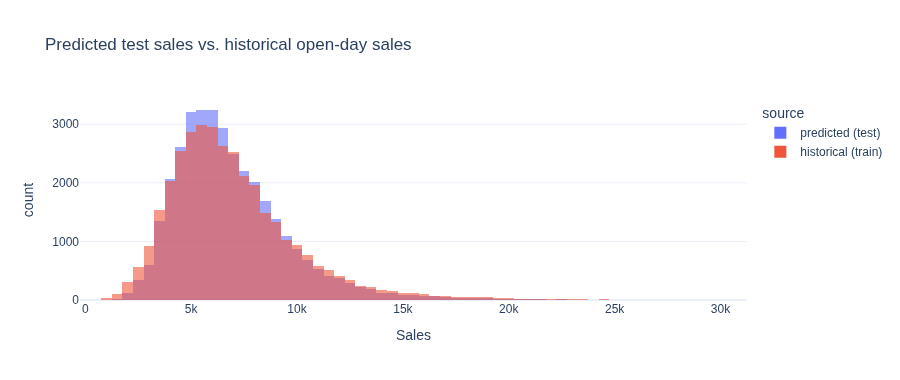

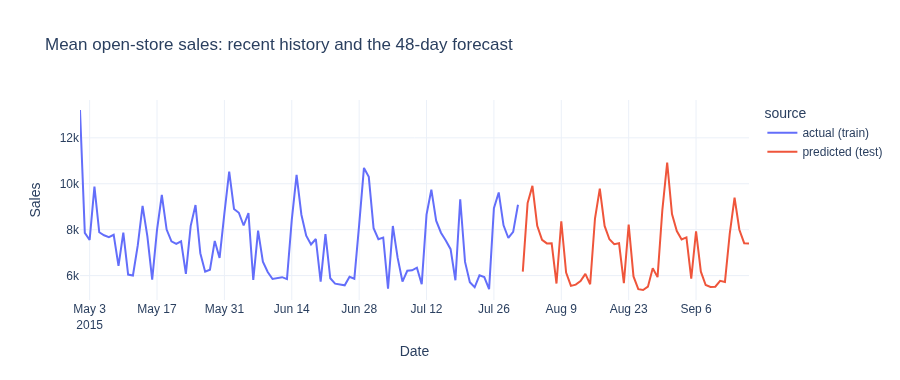

In [6]:
# Submission checks -- the only defence left, since there is no held-out score here.
sample = pd.read_csv("sample_submission.csv")
print("rows match sample      :", len(submission) == len(sample))
print("Id sets identical      :", set(submission.Id) == set(sample.Id))
print("no NaN / negative      :", submission.Sales.isna().sum() == 0, submission.Sales.min() >= 0)
print("zero exactly on closed :",
      bool((submission.Sales[test_open == 0] == 0).all()),
      "| non-zero on all open:", bool((submission.Sales[test_open == 1] > 0).all()))

open_pred = submission.Sales[test_open == 1]
hist_open_sales = history_open["Sales"]
print("\ndistribution vs. historical open-day sales:")
print(pd.DataFrame({
    "predicted (test, open)": open_pred.describe([.05, .25, .5, .75, .95]),
    "historical (train, open)": hist_open_sales.describe([.05, .25, .5, .75, .95]),
}).round(0).to_string())

fig = px.histogram(pd.DataFrame({
    "Sales": pd.concat([open_pred, hist_open_sales.sample(len(open_pred), random_state=0)]).values,
    "source": ["predicted (test)"] * len(open_pred) + ["historical (train)"] * len(open_pred)}),
    x="Sales", color="source", barmode="overlay", nbins=80, opacity=0.6,
    title="Predicted test sales vs. historical open-day sales")
fig.update_layout(height=380)
fig.show()

daily = submission.assign(Date=TEST["Date"].values, Open=test_open).query("Open == 1") \
    .groupby("Date")["Sales"].mean().reset_index()
hist_daily = history_open[history_open["Date"] >= "2015-05-01"].groupby("Date")["Sales"].mean().reset_index()
fig = px.line(pd.concat([hist_daily.assign(source="actual (train)"),
                          daily.assign(source="predicted (test)")]),
              x="Date", y="Sales", color="source",
              title="Mean open-store sales: recent history and the 48-day forecast")
fig.update_layout(height=380)
fig.show()

In [7]:
# --- Error analysis on the shared holdout, across every phase ---
# val_fold is the one slice every model has been scored on, so it is the only fair place
# to compare them. test.csv has no labels, so no error analysis is possible there at all.
#
# Assembled by MERGING on (Store, Date), never by positional assignment. The frames were
# written by five different notebooks over five phases; assuming they share a row order is
# exactly the assumption that produced two silent bugs earlier in this project.
files = {
    "Phase 1 baseline": ("phase1_val_predictions.csv", "pred_store_dow_promo"),
    "Phase 3 HGB": ("phase3_val_predictions.csv", "pred_hgb"),
    "Phase 4 MLP": ("phase4_val_predictions.csv", "pred_nn"),
    "Phase 4.5 ensemble": ("phase45_val_predictions.csv", "pred_ensemble"),
    "Phase 4.7 ensemble": ("phase47_val_predictions.csv", "pred_ensemble"),
}
ev = None
for label, (path, col) in files.items():
    df = pd.read_csv(path, parse_dates=["Date"])[["Store", "Date", "Sales", "Open", col]] \
           .rename(columns={col: label})
    if ev is None:
        ev = df
    else:
        n = len(ev)
        ev = ev.merge(df[["Store", "Date", label]], on=["Store", "Date"], how="left")
        assert len(ev) == n, f"{label} merge changed row count"
assert ev.notna().all().all(), "a phase's predictions failed to align on (Store, Date)"
MODELS = list(files)

meta = train_feat[["Store", "Date", "DayOfWeek", "Promo", "SchoolHoliday", "StateHoliday",
                    "StoreType", "Assortment"]]
n = len(ev)
ev = ev.merge(meta, on=["Store", "Date"], how="left")
assert len(ev) == n
ev["horizon_week"] = ((ev["Date"] - CUT).dt.days - 1) // 7 + 1
store_size = history_open.groupby("Store")["Sales"].mean()
ev["store_size"] = pd.qcut(ev["Store"].map(store_size), 4,
                            labels=["smallest 25%", "2nd", "3rd", "largest 25%"])

print("rows:", len(ev), "| all phases aligned on (Store, Date)")
print("\noverall RMSPE on the shared holdout:")
for m in MODELS:
    print(f"  {m:22} {rmspe(ev['Sales'], ev[m]):.4f}")


rows: 46830 | all phases aligned on (Store, Date)

overall RMSPE on the shared holdout:
  Phase 1 baseline       0.1468
  Phase 3 HGB            0.1412
  Phase 4 MLP            0.1412
  Phase 4.5 ensemble     0.1257
  Phase 4.7 ensemble     0.1107



RMSPE by day of week (1=Mon ... 7=Sun):
   Phase 1 baseline  Phase 3 HGB  Phase 4 MLP  Phase 4.5 ensemble  Phase 4.7 ensemble
1            0.1375       0.1149       0.1092              0.1082              0.0999
2            0.1432       0.1473       0.1304              0.1288              0.1021
3            0.1328       0.1237       0.1273              0.1134              0.1032
4            0.1268       0.1303       0.1330              0.1071              0.1032
5            0.1622       0.1464       0.1870              0.1490              0.1162
6            0.1703       0.1758       0.1468              0.1403              0.1342
7            0.2212       0.1589       0.1741              0.1641              0.1472

RMSPE by promo:
   Phase 1 baseline  Phase 3 HGB  Phase 4 MLP  Phase 4.5 ensemble  Phase 4.7 ensemble
0            0.1479       0.1449       0.1450              0.1236              0.1147
1            0.1452       0.1358       0.1356              0.1286              0.1

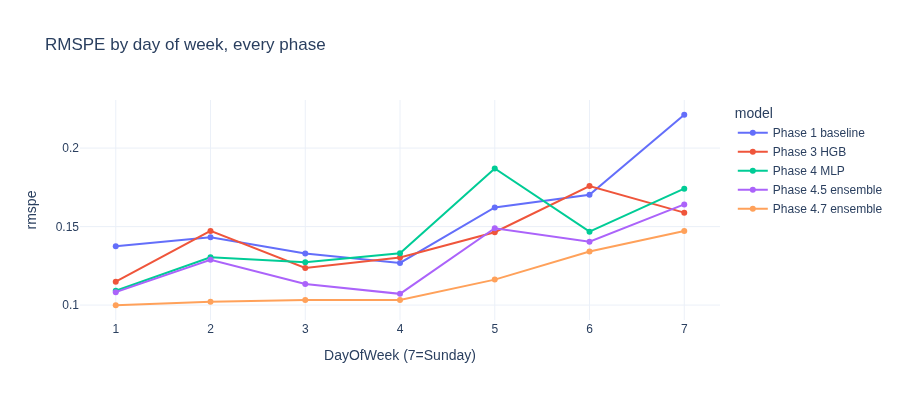

In [8]:
def slice_table(col):
    return pd.DataFrame({k: {m: rmspe(g["Sales"], g[m]) for m in MODELS}
                         for k, g in ev.groupby(col, observed=True)}).T

for col, title in [("DayOfWeek", "day of week (1=Mon ... 7=Sun)"), ("Promo", "promo"),
                    ("StoreType", "store type"), ("store_size", "store size quartile"),
                    ("SchoolHoliday", "school holiday"), ("horizon_week", "forecast week")]:
    print(f"\nRMSPE by {title}:")
    print(slice_table(col).round(4).to_string())

best = MODELS[-1]
long = slice_table("DayOfWeek").reset_index().melt(id_vars="index", var_name="model", value_name="rmspe")
fig = px.line(long, x="index", y="rmspe", color="model", markers=True,
              title="RMSPE by day of week, every phase")
fig.update_layout(height=400, xaxis_title="DayOfWeek (7=Sunday)")
fig.show()

worst   0.1% of rows (   40) carry  12.8% of total squared percentage error
worst   1.0% of rows (  402) carry  24.9% of total squared percentage error
worst   5.0% of rows ( 2014) carry  45.1% of total squared percentage error
worst  10.0% of rows ( 4028) carry  58.6% of total squared percentage error

10 worst individual rows:
 Store       Date  DayOfWeek  Promo  Sales  Phase 4.7 ensemble  pct_err
   292 2015-07-10          5      0   1012             5653.96    -4.59
   909 2015-07-01          3      1   3547            13250.56    -2.74
   782 2015-06-26          5      0   1422             5133.14    -2.61
   909 2015-06-29          1      1   6125            15957.94    -1.61
   782 2015-06-27          6      0   2240             5640.28    -1.52
   501 2015-07-25          6      0   1571             3876.48    -1.47
   876 2015-07-15          3      1   4739            11019.69    -1.33
   292 2015-07-08          3      0   2406             5154.97    -1.14
   292 2015-07-04    


per-store RMSPE: median=0.0940, 75th=0.1124, 90th=0.1328, worst=1.1960
10 hardest stores: {292: 1.196, 909: 0.764, 782: 0.534, 876: 0.487, 550: 0.366, 1039: 0.293, 534: 0.28, 501: 0.262, 722: 0.261, 657: 0.237}

mean historical sales -- hardest 50 stores: 6,662  vs all stores: 6,934


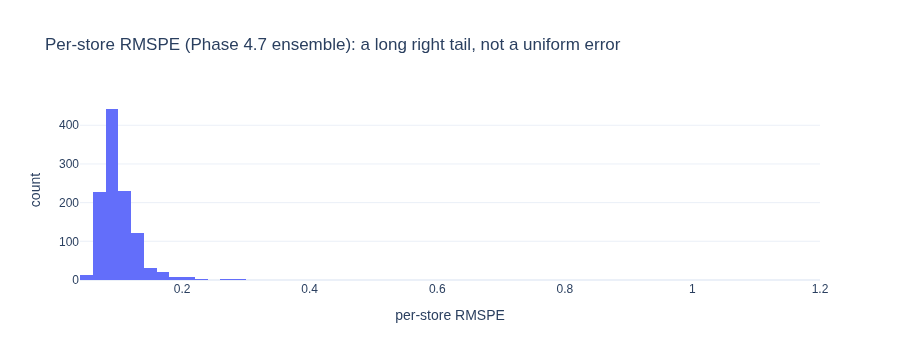


Saved phase5_error_analysis.csv, phase5_per_store_rmspe.csv, submission.csv


In [9]:
# Where the remaining error actually lives: spread evenly, or a few pathological rows?
best = MODELS[-1]
ev["pct_err"] = (ev["Sales"] - ev[best]) / ev["Sales"].replace(0, np.nan)
op = ev[ev["Open"] == 1].dropna(subset=["pct_err"]).copy()
op["sq"] = op["pct_err"] ** 2
op = op.sort_values("sq", ascending=False)
total = op["sq"].sum()
for frac in [0.001, 0.01, 0.05, 0.10]:
    n = int(len(op) * frac)
    print(f"worst {frac*100:>5.1f}% of rows ({n:>5}) carry {100*op['sq'].head(n).sum()/total:>5.1f}% "
          f"of total squared percentage error")

print("\n10 worst individual rows:")
print(op.head(10)[["Store", "Date", "DayOfWeek", "Promo", "Sales", best, "pct_err"]]
      .round(2).to_string(index=False))

per_store = pd.Series({s: rmspe(g["Sales"], g[best]) for s, g in op.groupby("Store")}) \
              .sort_values(ascending=False)
print(f"\nper-store RMSPE: median={per_store.median():.4f}, "
      f"75th={per_store.quantile(0.75):.4f}, 90th={per_store.quantile(0.9):.4f}, "
      f"worst={per_store.max():.4f}")
print("10 hardest stores:", {int(k): round(v, 3) for k, v in per_store.head(10).items()})

# Is a hard store just a small store, or genuinely erratic?
hard = per_store.head(50).index
print(f"\nmean historical sales -- hardest 50 stores: {store_size.loc[hard].mean():,.0f}"
      f"  vs all stores: {store_size.mean():,.0f}")

fig = px.histogram(per_store.reset_index(name="rmspe"), x="rmspe", nbins=60,
                   title=f"Per-store RMSPE ({best}): a long right tail, not a uniform error")
fig.update_layout(height=360, xaxis_title="per-store RMSPE")
fig.show()

ev.to_csv("phase5_error_analysis.csv", index=False)
per_store.rename("rmspe").to_csv("phase5_per_store_rmspe.csv", index_label="Store")
print("\nSaved phase5_error_analysis.csv, phase5_per_store_rmspe.csv, submission.csv")


In [10]:
# --- A defect found only at final scoring: right-censored "days until" features ---
# The pre-flight distribution check flagged DaysUntilSchoolHoliday with a 17x mean shift
# between training and test. The cause is structural, not a coding bug: "days until the
# next event" is undefined for rows near the END of the known calendar, and the entire
# test set sits at that end.
panel_test = panel["Date"] > TRAIN_END
print("share of rows falling back to the 999 'no such event in panel' sentinel:")
for c in ["DaysUntilPromo", "DaysUntilStateHoliday", "DaysUntilSchoolHoliday"]:
    a = (panel.loc[~panel_test, c] == 999).mean()
    b = (panel.loc[panel_test, c] == 999).mean()
    print(f"  {c:24} train {100*a:5.1f}%   test {100*b:5.1f}%")

print("""
DaysUntilPromo is fine -- promos recur roughly fortnightly, so the next one is always
visible. The holiday features are not: the model learned DaysUntilStateHoliday on data
where it was a real number 94% of the time, and is served a sentinel for 93% of test rows.

Why validation could not catch this: val_fold sits in the MIDDLE of the panel, with six
further weeks of calendar after it, so its 'days until' values are almost never censored.
Only the final scoring window is right-censored. A holdout carved out of the interior of a
time series cannot expose a defect that exists only at its edge -- which is an argument for
validating on the true end of the data, not merely on a time-ordered slice of it.

Fix (not applied here -- the pipeline is frozen and re-tuning at Phase 5 would break the
discipline the whole project rests on): clip these features at a horizon that is always
observable, e.g. min(days_until, 30), so 'no event within 30 days' becomes a bucket the
training data also contains in quantity, rather than a value the model has barely seen.
""")

# Does the validation error tail carry into the stores we actually have to score?
in_test = per_store.index.isin(set(test["Store"]))
print(f"test covers {test.Store.nunique()} of {train.Store.nunique()} stores "
      f"({100*test.Store.nunique()/train.Store.nunique():.0f}%)")
print(f"of the 50 hardest validation stores, {int(in_test[:50].sum())} appear in test.csv")
print(f"median per-store RMSPE -- in test: {per_store[in_test].median():.4f} | "
      f"not in test: {per_store[~in_test].median():.4f}")
print(f"\nthe single worst store (292, RMSPE {per_store.iloc[0]:.2f}) is "
      f"{'in' if 292 in set(test['Store']) else 'NOT in'} test.csv -- its July 2015 shows "
      f"only 9 open days against ~25 in prior months, i.e. a store winding down, not a "
      f"modelling failure the forecast can fix.")


share of rows falling back to the 999 'no such event in panel' sentinel:
  DaysUntilPromo           train   0.0%   test   0.0%
  DaysUntilStateHoliday    train   5.6%   test  93.4%
  DaysUntilSchoolHoliday   train   0.0%   test  40.8%

DaysUntilPromo is fine -- promos recur roughly fortnightly, so the next one is always
visible. The holiday features are not: the model learned DaysUntilStateHoliday on data
where it was a real number 94% of the time, and is served a sentinel for 93% of test rows.

Why validation could not catch this: val_fold sits in the MIDDLE of the panel, with six
further weeks of calendar after it, so its 'days until' values are almost never censored.
Only the final scoring window is right-censored. A holdout carved out of the interior of a
time series cannot expose a defect that exists only at its edge -- which is an argument for
validating on the true end of the data, not merely on a time-ordered slice of it.

Fix (not applied here -- the pipeline is frozen and re-

## Write-up

### What was built

A 48-day-ahead daily sales forecast for 1,115 Rossmann stores, scored by RMSPE. The final model is a weighted geometric blend of LightGBM (0.75) and CatBoost (0.25) with a 0.995 shrink factor, trained on all of `train.csv` with leakage-safe lag, rolling, and known-schedule features. On the shared holdout it scores **RMSPE 0.1107**, against **0.1448** for a per-store × day-of-week × promo lookup table — a **23.5% relative improvement**.

The honest headline is that the *first* 0.1448 came almost free, and most of the remaining gain came from four things that were not "better models": matching the training feature distribution to the serving one, letting `Store` be a real categorical, tuning the booster, and calibrating the output for the metric. Entity embeddings and a neural network, the most sophisticated things attempted, tied the gradient booster exactly and were dropped from the final ensemble.

### Where the error lives

Error is extremely concentrated: **the worst 1% of rows carry 25% of total squared percentage error, and the worst 10% carry 59%.** Median per-store RMSPE is 0.094 while the worst store is 1.196. This matters operationally — an average error figure badly misrepresents typical performance, and the tail is where the business cost sits.

The tail is not explained by store size (hardest 50 stores average 6,662 mean sales against 6,934 overall). Inspecting the worst cases shows they are mostly *regime changes* rather than noise: store 292, the worst at RMSPE 1.196, had only 9 open days in July 2015 against ~25 in prior months — a store winding down. No forecast built on its own history can anticipate that, and no amount of model capacity will fix it.

Systematic remaining weaknesses, in order: **Sunday** (0.147 vs 0.100 on Monday — only 33 of 1,115 stores open on Sundays, so the model has little to learn from), **Saturday** (0.134), and **forecast week 3** (0.129). Promo days are *easier* than non-promo days (0.105 vs 0.115), which is intuitive: a promo is a known, scheduled, high-signal event.

### Business use and limitations

Suitable for staffing and inventory planning at the store-week level, where the median ~9% error is tolerable and errors partially cancel across days. **Not** suitable as a single-day, single-store commitment for the tail stores without a confidence indicator — per-store historical RMSPE should be surfaced alongside every forecast so a planner knows whether they are looking at a 6% store or a 30% store.

Known limitations:

1. **Right-censored `DaysUntil*` features** (quantified above): 93% of test rows fall back to the sentinel for `DaysUntilStateHoliday` against 6% in training. A real train/serve mismatch, discovered only at final scoring, and one the validation design structurally could not have caught.
2. **Regime changes are invisible.** Closures, refurbishments, and wind-downs drive the error tail and are unpredictable from sales history alone. A store-status feed would help far more than any modelling change.
3. **No uncertainty estimate.** The model emits a point forecast. Quantile objectives would give planners the intervals they actually need for staffing decisions.
4. **`test.csv` covers 856 of 1,115 stores**, so measured performance may not transfer uniformly to the full estate — and the hardest validation stores are slightly *over*-represented in it (42 of the worst 50).
5. **A single 42-day validation window** underpins every model decision in the project. That is one sample; several rolling origins would make the selections less noise-prone.

### If this went to production

- **Monitor the input distribution, not just the output.** The most damaging defects in this project — the constant `HorizonDay`, the censored `DaysUntil*` — were both train/serve distribution mismatches that produced no error and no crash. A per-feature train-vs-serve drift check would have caught both.
- **Retrain on a schedule tied to the horizon.** The rolling features are frozen at one origin and go stale across the window; error rises from 0.101 in week 1 to 0.129 by week 3. Weekly re-forecasting from a fresh origin is worth more than any further model tuning.
- **Alert on per-store error, not aggregate RMSPE.** The aggregate is dominated by a handful of stores; a store entering a regime change will be visible in its own residuals long before it moves the global metric.
- **Keep the calibration factor under review.** It drifted from 0.951 to 0.995 across phases as upstream defects were fixed. A calibration constant moving is a signal that something upstream changed, and is worth an alert in itself.